# AcousticSense: Autoencoders for Acoustic Anomaly Detection (MIMII fan)

One-class / unsupervised anomaly detection on industrial machinery audio. Models are trained **only on healthy audio**; the per-sample reconstruction MSE is the anomaly score.

Two architectures are trained on the same leak-free split and compared:

1. **Conv AE (spec)** - 2D convolutional autoencoder from `CLAUDE.md` (no skip connections, tight bottleneck).
2. **Dense 5-frame AE** - the architecture family behind the best published autoencoder numbers on MIMII fan (original MIMII benchmark: 0.75 AUC on id_00; DCASE 2020 dense AE beat the conv AE on fan on average).

**Sections**

1. Config & imports
2. Data discovery & leak-free split
3. Log-Mel preprocessing (channel 0, cached) + `tf.data` loaders
4. Conv AE: `build_conv_autoencoder`
5. Conv AE training
6. Conv AE scoring & clip aggregation
7. Visual diagnostics
8. Evaluation suite (`evaluate()`): ROC, AUC, pAUC, histograms, F1 / confusion matrix
9. Dense 5-frame AE: data, model, training, evaluation
10. Model comparison

**Expected data layout** (MIMII): `DATA_DIR/normal/*.wav` and `DATA_DIR/abnormal/*.wav`. If `DATA_DIR` is missing, a small synthetic dataset is generated so the notebook still runs.


## 1. Config & imports


In [1]:
import os
import glob
import random
import hashlib
from pathlib import Path

import numpy as np
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.metrics import (roc_auc_score, roc_curve, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ---- Paths ----
# expects normal/ and abnormal/ subfolders
DATA_DIR = Path("../fan/id_02")
# preprocessed spectrograms (gitignored)
CACHE_DIR = Path("../data/cache")
# MIMII is 8-channel; benchmark uses mic 1 only. None = average all
CHANNEL = 0
SYNTH_DIR = Path("../data/synthetic")           # used only if DATA_DIR is missing

# ---- Audio / spectrogram ----
SR = 16000
N_FFT = 1024
HOP = 512
N_MELS = 128
# ~2.05 s -> 65 frames (center=True), cropped to T=64
WINDOW_SAMPLES = 32768
OVERLAP = 0.5
T = 64                                       # time frames, power of 2

# ---- Model / training ----
LATENT_DIM = 32
USE_SE = False
BATCH_SIZE = 32
EPOCHS = int(os.environ.get("EPOCHS", 100))   # override for quick smoke tests
LR = 1e-3
LOSS = "mse"                                 # or "mae"
# random gain augmentation (+/- dB), train only
GAIN_DB = 2.0
THRESHOLD_PERCENTILE = 95
# "mean" or "max" for segment -> clip aggregation
CLIP_AGG = "mean"

# ---- Dense 5-frame AE ----
# consecutive frames stacked per input vector
CTX = 5
DENSE_LATENT = 16
DENSE_HIDDEN = (1024, 512, 256, 128)
DENSE_BATCH = 512
# frame stride when building training vectors (memory)
DENSE_TRAIN_STRIDE = 2

print("TF", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1794880123.215898    7419 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794880123.388209    7419 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794880124.598978    7419 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TF 2.22.0-rc0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data discovery & leak-free split

The split is done **at the clip (file) level before slicing into windows**, so overlapping windows
from one clip can never appear in two different splits.

| Split | Contents                                                                  |
| ----- | ------------------------------------------------------------------------- |
| train | healthy clips only (70%)                                                  |
| val   | healthy clips only (10%), used for early stopping and threshold selection |
| test  | remaining healthy clips (20%) + **all** faulty clips                      |


In [2]:
def make_synthetic_dataset(out_dir, n_normal=60, n_abnormal=20, dur=10.0, sr=SR, seed=SEED):
    """Tiny stand-in dataset: hum + noise (normal); same plus random clicks / extra tone (abnormal)."""
    rng = np.random.default_rng(seed)
    for sub in ("normal", "abnormal"):
        (out_dir / sub).mkdir(parents=True, exist_ok=True)
    t = np.arange(int(dur * sr)) / sr

    def base():
        f0 = 120 + rng.normal(0, 2)
        x = 0.3*np.sin(2*np.pi*f0*t) + 0.15*np.sin(2*np.pi*2 *
                                                   f0*t) + 0.05*rng.standard_normal(t.size)
        return x
    for i in range(n_normal):
        sf.write(out_dir/"normal"/f"{i:05d}.wav",
                 base().astype(np.float32), sr)
    for i in range(n_abnormal):
        x = base() + 0.2*np.sin(2*np.pi*1500*t)*(rng.random() > 0.5)
        for _ in range(rng.integers(3, 8)):
            c = rng.integers(0, t.size - 400)
            x[c:c+400] += rng.normal(0, 0.8, 400)
        sf.write(out_dir/"abnormal"/f"{i:05d}.wav", x.astype(np.float32), sr)


if not (DATA_DIR / "normal").exists():
    print(f"{DATA_DIR} not found -> using synthetic data in {SYNTH_DIR}")
    if not (SYNTH_DIR / "normal").exists():
        make_synthetic_dataset(SYNTH_DIR)
    DATA_DIR = SYNTH_DIR

normal_files = sorted(glob.glob(str(DATA_DIR / "normal" / "*.wav")))
abnormal_files = sorted(glob.glob(str(DATA_DIR / "abnormal" / "*.wav")))
print(f"normal: {len(normal_files)} | abnormal: {len(abnormal_files)}")
assert normal_files and abnormal_files, "Need both normal/ and abnormal/ clips"

rng = np.random.default_rng(SEED)
perm = rng.permutation(len(normal_files))
n_train = int(0.7 * len(perm))
n_val = int(0.1 * len(perm))
train_files = [normal_files[i] for i in perm[:n_train]]
val_files = [normal_files[i] for i in perm[n_train:n_train + n_val]]
test_normal = [normal_files[i] for i in perm[n_train + n_val:]]
test_files = test_normal + abnormal_files
test_labels = np.array([0]*len(test_normal) + [1] *
                       len(abnormal_files))   # 1 = anomaly

# zero-leakage check
assert not (set(train_files) & set(val_files)) and not (set(train_files) & set(test_files)) \
    and not (set(val_files) & set(test_files))
print(f"train {len(train_files)} | val {len(val_files)} | test {len(test_files)} "
      f"({len(test_normal)} healthy + {len(abnormal_files)} faulty)")

normal: 1016 | abnormal: 359
train 711 | val 101 | test 563 (204 healthy + 359 faulty)


## 3. Log-Mel preprocessing + `tf.data` loaders

- Slice each clip into fixed windows (50% overlap) -> log-Mel (`melspectrogram` + `power_to_db`).
- Pad/crop time axis to `T` (power of 2).
- Min-Max scale to [0, 1] using `train_min` / `train_max` fitted **on the healthy training set only**.
- Only augmentation: random gain of +/- 2 dB (training set only).


In [3]:
def load_audio(path, sr=SR):
    # (channels, samples) or (samples,)
    y, _ = librosa.load(path, sr=sr, mono=False)
    y = np.atleast_2d(y)
    return y.mean(axis=0) if CHANNEL is None else y[CHANNEL]


def slice_windows(y, win=WINDOW_SAMPLES, overlap=OVERLAP):
    step = int(win * (1 - overlap))
    if len(y) < win:
        y = np.pad(y, (0, win - len(y)))
    starts = range(0, len(y) - win + 1, step)
    return np.stack([y[s:s + win] for s in starts])


def pad_crop_time(S, T=T, pad_value=None):
    """S: (n_mels, frames) -> (n_mels, T)."""
    frames = S.shape[1]
    if frames >= T:
        return S[:, :T]
    pv = S.min() if pad_value is None else pad_value
    return np.pad(S, ((0, 0), (0, T - frames)), constant_values=pv)


def log_mel(y):
    M = librosa.feature.melspectrogram(
        y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
    # fixed reference -> comparable across clips
    return librosa.power_to_db(M, ref=1.0)


def clip_to_segments(path):
    """Returns (n_segments, 128, T) raw dB spectrograms for one clip."""
    wins = slice_windows(load_audio(path))
    return np.stack([pad_crop_time(log_mel(w)) for w in wins]).astype(np.float32)


def build_split(files, name):
    """Returns X (N,128,T) in dB and clip_ids (N,) mapping each segment to its clip index. Cached on disk."""
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    sig = "|".join(
        files) + f"|ch{CHANNEL}|w{WINDOW_SAMPLES}|o{OVERLAP}|T{T}|m{N_MELS}|h{HOP}|f{N_FFT}"
    cache = CACHE_DIR / \
        f"{name}_{hashlib.md5(sig.encode()).hexdigest()[:12]}.npz"
    if cache.exists():
        d = np.load(cache)
        print(f"[cache] {name}")
        return d["X"], d["ids"]
    Xs, ids = [], []
    for i, f in enumerate(files):
        segs = clip_to_segments(f)
        Xs.append(segs)
        ids.append(np.full(len(segs), i))
    X, ids = np.concatenate(Xs), np.concatenate(ids)
    np.savez(cache, X=X, ids=ids)
    return X, ids


X_train_db, ids_train = build_split(train_files, "train")
X_val_db,   ids_val = build_split(val_files, "val")
X_test_db,  ids_test = build_split(test_files, "test")
print("segments  train/val/test:",
      X_train_db.shape[0], X_val_db.shape[0], X_test_db.shape[0])

# Min-Max statistics from the healthy TRAIN set only
TRAIN_MIN, TRAIN_MAX = float(X_train_db.min()), float(X_train_db.max())
print(f"train_min={TRAIN_MIN:.2f} dB, train_max={TRAIN_MAX:.2f} dB")


def normalize(X_db):
    X = (X_db - TRAIN_MIN) / (TRAIN_MAX - TRAIN_MIN)
    # (N,128,T,1)
    return np.clip(X, 0.0, 1.0)[..., np.newaxis].astype(np.float32)


X_train, X_val, X_test = map(normalize, (X_train_db, X_val_db, X_test_db))
INPUT_SHAPE = X_train.shape[1:]
print("input shape:", INPUT_SHAPE)

[cache] train
[cache] val
[cache] test
segments  train/val/test: 5688 808 4504
train_min=-60.47 dB, train_max=5.71 dB
input shape: (128, 64, 1)


In [4]:
# +/- 2 dB expressed in normalized units
GAIN_NORM = GAIN_DB / (TRAIN_MAX - TRAIN_MIN)


def random_gain(x):
    g = tf.random.uniform([], -GAIN_NORM, GAIN_NORM)
    return tf.clip_by_value(x + g, 0.0, 1.0)


def make_ds(X, training):
    ds = tf.data.Dataset.from_tensor_slices(X)
    if training:
        ds = ds.cache().shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
        ds = ds.map(random_gain, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = ds.cache()
    # autoencoder: target = input
    ds = ds.map(lambda x: (x, x), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_ds(X_train, training=True)
val_ds = make_ds(X_val,   training=False)

I0000 00:00:1794880127.639805    7419 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4176 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


## 4. Model

Symmetric conv encoder/decoder, tight dense bottleneck, **no skip connections**.


In [5]:
def se_block(x, ratio=8):
    ch = x.shape[-1]
    s = layers.GlobalAveragePooling2D()(x)
    s = layers.Dense(max(ch // ratio, 4), activation="relu")(s)
    s = layers.Dense(ch, activation="sigmoid")(s)
    s = layers.Reshape((1, 1, ch))(s)
    return layers.Multiply()([x, s])


def build_conv_autoencoder(input_shape, latent_dim=32, use_se=False):
    inp = layers.Input(shape=input_shape, name="spectrogram")
    x = inp

    # ---- Encoder ----
    for f in (32, 64, 128, 256):
        x = layers.Conv2D(f, 3, strides=2, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.LeakyReLU(alpha=0.2)(x)
        if use_se:
            x = se_block(x)

    # ---- Bottleneck ----
    # (H_enc, W_enc, 256)
    h_enc, w_enc, c_enc = x.shape[1], x.shape[2], x.shape[3]
    x = layers.Flatten()(x)
    z = layers.Dense(latent_dim, name="bottleneck")(x)

    # ---- Decoder ----
    x = layers.Dense(h_enc * w_enc * c_enc)(z)
    x = layers.LeakyReLU(alpha=0.2)(x)
    x = layers.Reshape((h_enc, w_enc, c_enc))(x)
    for f in (128, 64, 32, 16):
        x = layers.Conv2DTranspose(f, 3, strides=2, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.LeakyReLU(alpha=0.2)(x)
    out = layers.Conv2D(1, 3, padding="same",
                        activation="sigmoid", name="reconstruction")(x)

    return Model(inp, out, name="conv_autoencoder" + ("_se" if use_se else ""))


model = build_conv_autoencoder(
    INPUT_SHAPE, latent_dim=LATENT_DIM, use_se=USE_SE)
assert model.output_shape[1:] == tuple(
    INPUT_SHAPE), (model.output_shape, INPUT_SHAPE)
model.summary()

/home/parallax/projects/AcousticSense/.venv/lib64/python3.14/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Model: "conv_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ spectrogram (InputLayer)        │ (None, 128, 64, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 64, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 8, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 8, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 8, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 8, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │       262,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8192)           │       270,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 8, 128)     │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 8, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 16, 8, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 16, 64)     │        73,79

 Total params: 1,315,297 (5.02 MB)

 Trainable params: 1,313,857 (5.01 MB)

 Non-trainable params: 1,440 (5.62 KB)

## 5. Training


Epoch 1/100


/home/parallax/projects/AcousticSense/.venv/lib64/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794880130.850674    7419 service.cc:154] XLA service 0x5585818b1500 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794880130.850691    7419 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6 (Driver: 13.5.0[620.70.6]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794880130.917582    7419 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1794880131.535245    7419 cuda_dnn.cc:442] Loaded cuDNN version 92801
I0000 00:00:1794880133.

178/178 - 16s - 93ms/step - loss: 0.0045 - val_loss: 0.0129 - learning_rate: 0.0010
Epoch 2/100
178/178 - 3s - 16ms/step - loss: 0.0027 - val_loss: 0.0098 - learning_rate: 0.0010
Epoch 3/100
178/178 - 3s - 16ms/step - loss: 0.0025 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 4/100
178/178 - 3s - 16ms/step - loss: 0.0024 - val_loss: 0.0024 - learning_rate: 0.0010
Epoch 5/100
178/178 - 3s - 16ms/step - loss: 0.0023 - val_loss: 0.0024 - learning_rate: 0.0010
Epoch 6/100
178/178 - 3s - 16ms/step - loss: 0.0023 - val_loss: 0.0023 - learning_rate: 0.0010
Epoch 7/100
178/178 - 3s - 16ms/step - loss: 0.0023 - val_loss: 0.0024 - learning_rate: 0.0010
Epoch 8/100
178/178 - 3s - 16ms/step - loss: 0.0022 - val_loss: 0.0022 - learning_rate: 0.0010
Epoch 9/100
178/178 - 3s - 16ms/step - loss: 0.0022 - val_loss: 0.0024 - learning_rate: 0.0010
Epoch 10/100
178/178 - 3s - 16ms/step - loss: 0.0022 - val_loss: 0.0025 - learning_rate: 0.0010
Epoch 11/100
178/178 - 3s - 16ms/step - loss: 0.0022 - val_l

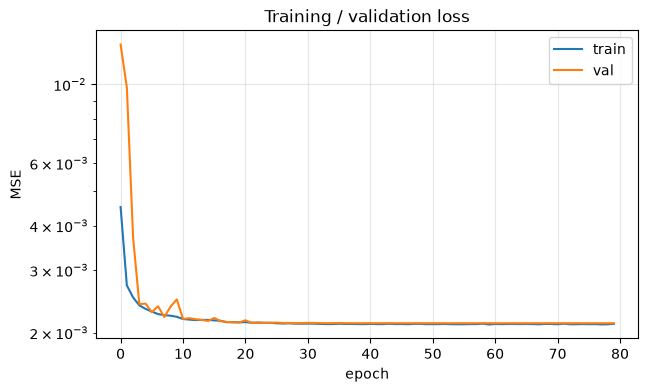

In [6]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR), loss=LOSS)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6),
]

history = model.fit(train_ds, validation_data=val_ds,
                    epochs=EPOCHS, callbacks=callbacks, verbose=2)

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.xlabel("epoch")
plt.ylabel(LOSS.upper())
plt.yscale("log")
plt.title("Training / validation loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Scoring & clip-level aggregation

Per-segment MSE, then aggregated (mean or max) back to one score per clip.


In [7]:
def segment_scores(X, batch_size=64):
    recon = model.predict(X, batch_size=batch_size, verbose=0)
    return np.mean(np.square(X - recon), axis=(1, 2, 3)), recon


def aggregate_to_clips(seg_scores, clip_ids, how=CLIP_AGG):
    fn = np.mean if how == "mean" else np.max
    return np.array([fn(seg_scores[clip_ids == c]) for c in np.unique(clip_ids)])


val_seg_scores,  _ = segment_scores(X_val)
test_seg_scores, recon_test = segment_scores(X_test)

val_clip_scores = aggregate_to_clips(val_seg_scores,  ids_val)
test_clip_scores = aggregate_to_clips(test_seg_scores, ids_test)
print("val clip scores:", val_clip_scores.shape,
      "| test clip scores:", test_clip_scores.shape)

val clip scores: (101,) | test clip scores: (563,)


## 7. Visual diagnostics

Original vs. reconstructed spectrogram and absolute pixel-wise error heatmap, for healthy vs. faulty test segments.
Each row is one example (the segment with the median score within its class, plus the worst-scoring faulty one).


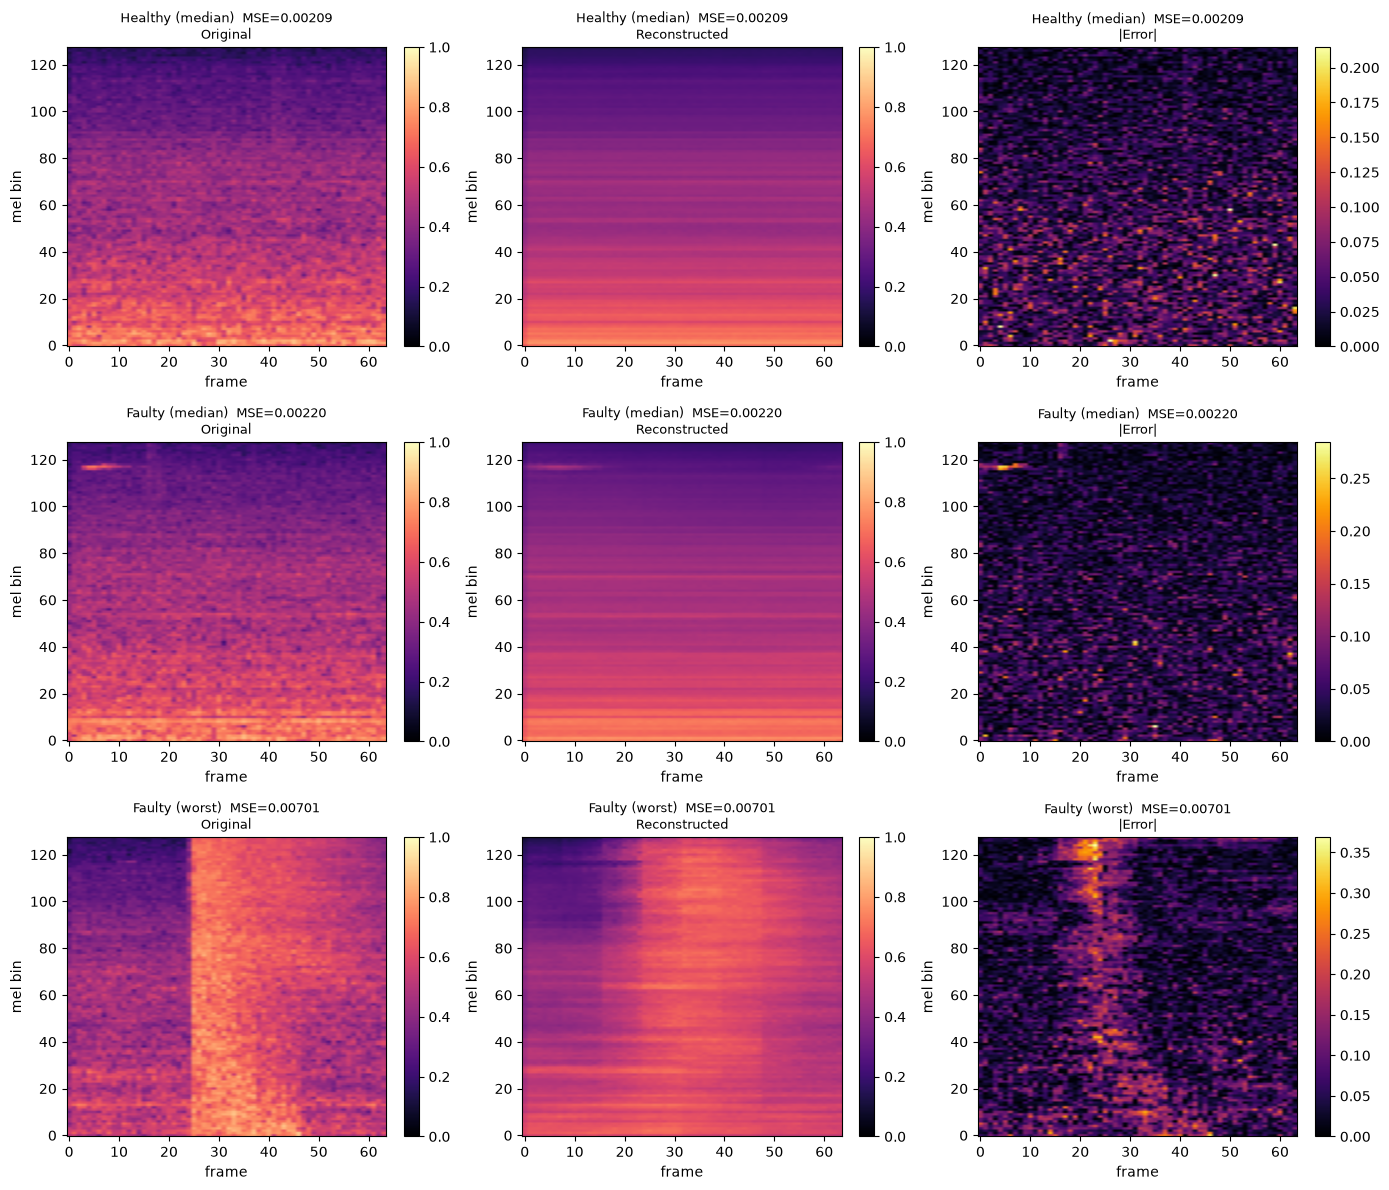

In [8]:
# label of each test segment
seg_labels = test_labels[ids_test]


def plot_triplet(axs, idx, title):
    orig, rec = X_test[idx, ..., 0], recon_test[idx, ..., 0]
    err = np.abs(orig - rec)
    for ax, img, name, cmap in zip(axs, (orig, rec, err),
                                   ("Original", "Reconstructed", "|Error|"),
                                   ("magma", "magma", "inferno")):
        im = ax.imshow(img, origin="lower", aspect="auto", cmap=cmap,
                       vmin=0, vmax=1 if name != "|Error|" else None)
        ax.set_title(f"{title}\n{name}", fontsize=9)
        ax.set_xlabel("frame")
        ax.set_ylabel("mel bin")
        plt.colorbar(im, ax=ax, fraction=0.046)


def median_idx(mask):
    idxs = np.where(mask)[0]
    return idxs[np.argsort(test_seg_scores[idxs])[len(idxs) // 2]]


picks = [
    (median_idx(seg_labels == 0), "Healthy (median)"),
    (median_idx(seg_labels == 1), "Faulty (median)"),
    (np.where(seg_labels == 1)[0][np.argmax(
        test_seg_scores[seg_labels == 1])], "Faulty (worst)"),
]
fig, axes = plt.subplots(len(picks), 3, figsize=(14, 4 * len(picks)))
for row, (i, name) in zip(axes, picks):
    plot_triplet(row, i, f"{name}  MSE={test_seg_scores[i]:.5f}")
plt.tight_layout()
plt.show()

## 8. Evaluation suite

`evaluate()` is reused for every model:

- **AUC-ROC** and **pAUC** (`max_fpr=0.1`; scikit-learn returns the McClish-standardized value, 0.5 = chance, 1.0 = perfect).
- **Threshold** = 95th percentile of healthy _validation_ clip scores (no test information used).
- **F1 / confusion matrix** at that threshold.


[Conv AE (spec)]
  AUC-ROC : 0.6954
  pAUC@0.1: 0.5535  (standardized)
  Threshold (P95 of healthy val): 0.002432
  F1-score: 0.2751
  Confusion matrix [rows=true, cols=pred]:
 [[193  11]
 [300  59]]


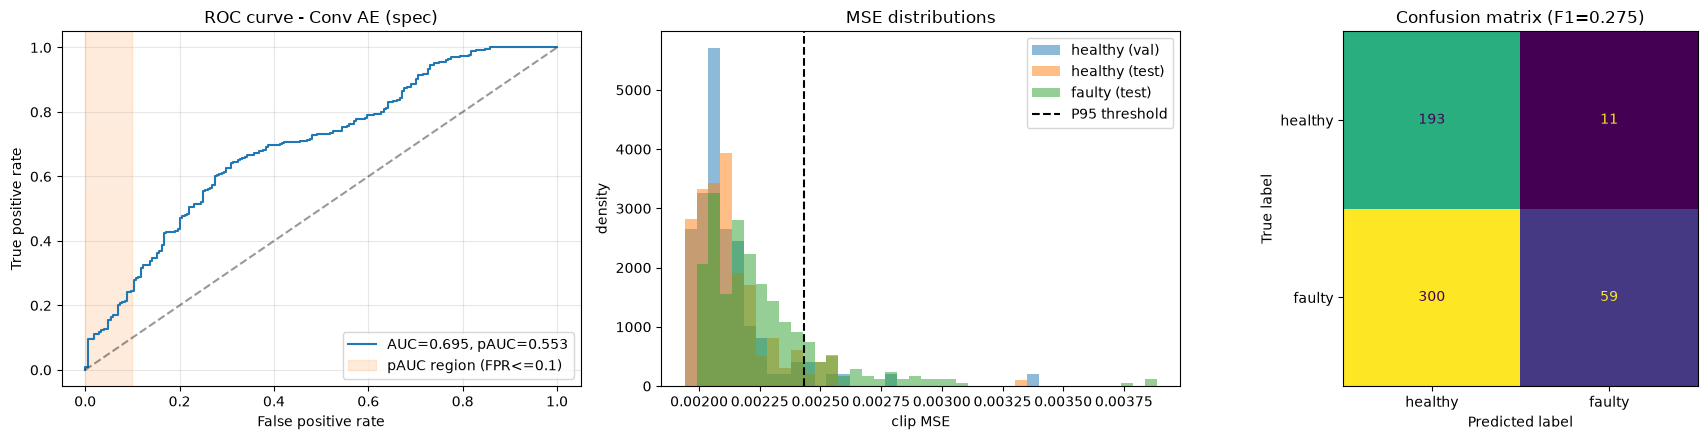

{'auc': 0.6953957070293298,
 'pauc': 0.5534695332465196,
 'f1': 0.27505827505827507,
 'threshold': np.float32(0.0024316316),
 'fpr': array([0.        , 0.        , 0.        , 0.00490196, 0.00490196,
        0.01960784, 0.01960784, 0.02941176, 0.02941176, 0.03431373,
        0.03431373, 0.03921569, 0.03921569, 0.04901961, 0.04901961,
        0.05392157, 0.05392157, 0.05882353, 0.05882353, 0.06862745,
        0.06862745, 0.07352941, 0.07352941, 0.07843137, 0.07843137,
        0.08333333, 0.08333333, 0.08823529, 0.08823529, 0.09803922,
        0.09803922, 0.10294118, 0.10294118, 0.10784314, 0.10784314,
        0.1127451 , 0.1127451 , 0.11764706, 0.11764706, 0.12254902,
        0.12254902, 0.1372549 , 0.1372549 , 0.14215686, 0.14215686,
        0.15196078, 0.15196078, 0.15686275, 0.15686275, 0.16176471,
        0.16176471, 0.16666667, 0.16666667, 0.17156863, 0.17156863,
        0.19117647, 0.19117647, 0.19607843, 0.19607843, 0.20098039,
        0.20098039, 0.20588235, 0.20588235, 0.210784

In [9]:
results = {}      # model name -> metrics, filled by evaluate()


def evaluate(name, val_clip_scores, test_clip_scores, plot=True):
    auc = roc_auc_score(test_labels, test_clip_scores)
    pauc = roc_auc_score(test_labels, test_clip_scores, max_fpr=0.1)
    threshold = np.percentile(val_clip_scores, THRESHOLD_PERCENTILE)
    y_pred = (test_clip_scores > threshold).astype(int)
    f1 = f1_score(test_labels, y_pred)
    cm = confusion_matrix(test_labels, y_pred)
    fpr, tpr, _ = roc_curve(test_labels, test_clip_scores)
    results[name] = dict(auc=auc, pauc=pauc, f1=f1,
                         threshold=threshold, fpr=fpr, tpr=tpr)

    print(f"[{name}]")
    print(f"  AUC-ROC : {auc:.4f}")
    print(f"  pAUC@0.1: {pauc:.4f}  (standardized)")
    print(
        f"  Threshold (P{THRESHOLD_PERCENTILE} of healthy val): {threshold:.6f}")
    print(f"  F1-score: {f1:.4f}")
    print("  Confusion matrix [rows=true, cols=pred]:\n", cm)
    if not plot:
        return results[name]

    fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
    axs[0].plot(fpr, tpr, label=f"AUC={auc:.3f}, pAUC={pauc:.3f}")
    axs[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
    axs[0].axvspan(0, 0.1, color="tab:orange", alpha=0.15,
                   label="pAUC region (FPR<=0.1)")
    axs[0].set(xlabel="False positive rate",
               ylabel="True positive rate", title=f"ROC curve - {name}")
    axs[0].legend(loc="lower right")
    axs[0].grid(alpha=0.3)

    bins = np.histogram_bin_edges(np.concatenate(
        [val_clip_scores, test_clip_scores]), bins=40)
    axs[1].hist(val_clip_scores, bins=bins, alpha=0.5,
                density=True, label="healthy (val)")
    axs[1].hist(test_clip_scores[test_labels == 0], bins=bins,
                alpha=0.5, density=True, label="healthy (test)")
    axs[1].hist(test_clip_scores[test_labels == 1], bins=bins,
                alpha=0.5, density=True, label="faulty (test)")
    axs[1].axvline(threshold, color="k", ls="--",
                   label=f"P{THRESHOLD_PERCENTILE} threshold")
    axs[1].set(xlabel="clip MSE", ylabel="density", title="MSE distributions")
    axs[1].legend()

    ConfusionMatrixDisplay(cm, display_labels=["healthy", "faulty"]).plot(
        ax=axs[2], colorbar=False)
    axs[2].set_title(f"Confusion matrix (F1={f1:.3f})")
    plt.tight_layout()
    plt.show()
    return results[name]


evaluate("Conv AE (spec)", val_clip_scores, test_clip_scores)

## 9. Dense 5-frame autoencoder

Same family as the original MIMII benchmark and the DCASE 2020 baseline / tuned AE: each input is **5 consecutive log-Mel frames stacked into one 640-dim vector** (5 x 128 mels). The network is a symmetric fully-connected autoencoder with a tiny bottleneck (16), using `1024-512-256-128-16-128-256-512-1024` with BatchNorm + ReLU, and a linear output.

Differences from the Conv AE:

- Input is a short local context, so brief changes (clicks, tones) are not diluted across a 2 s image.
- Features are **standardized per mel bin** (mean/std fitted on the healthy train set only) instead of global min-max, so quiet and loud bins contribute comparably.
- The clip score is the mean error over all 5-frame vectors in the clip.
- Training uses no gain augmentation (not meaningful after per-bin standardization).


In [10]:
# (1, 128, 1) per-mel-bin stats, TRAIN only
mu = X_train_db.mean(axis=(0, 2), keepdims=True)
sd = X_train_db.std(axis=(0, 2), keepdims=True) + 1e-6


def to_context_vectors(X_db, stride=1):
    """(N, 128, T) dB -> (N, frames, CTX*128): standardized, CTX consecutive frames stacked."""
    Z = ((X_db - mu) / sd).astype(np.float32)
    W = np.lib.stride_tricks.sliding_window_view(
        Z, CTX, axis=2)   # (N, 128, T-CTX+1, CTX)
    # (N, frames, CTX, 128)
    W = W[:, :, ::stride].transpose(0, 2, 3, 1)
    return W.reshape(W.shape[0], W.shape[1], CTX * N_MELS)


D_IN = CTX * N_MELS
V_train = to_context_vectors(X_train_db, DENSE_TRAIN_STRIDE).reshape(-1, D_IN)
V_val = to_context_vectors(X_val_db,   DENSE_TRAIN_STRIDE).reshape(-1, D_IN)
print("dense train / val vectors:", V_train.shape, V_val.shape,
      f"({V_train.nbytes / 1e6:.0f} MB + {V_val.nbytes / 1e6:.0f} MB)")


def make_dense_ds(V, training):
    ds = tf.data.Dataset.from_tensor_slices(V)
    if training:
        ds = ds.shuffle(50_000, seed=SEED, reshuffle_each_iteration=True)
    return ds.map(lambda x: (x, x), num_parallel_calls=tf.data.AUTOTUNE).batch(DENSE_BATCH).prefetch(tf.data.AUTOTUNE)


dense_train_ds = make_dense_ds(V_train, True)
dense_val_ds = make_dense_ds(V_val, False)

dense train / val vectors: (170640, 640) (24240, 640) (437 MB + 62 MB)


Model: "dense_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ stacked_frames (InputLayer)     │ (None, 640)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │       656,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 16)             │         2,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 2,710,992 (10.34 MB)

 Trainable params: 2,703,280 (10.31 MB)

 Non-trainable params: 7,712 (30.12 KB)

Epoch 1/100


/home/parallax/projects/AcousticSense/.venv/lib64/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794880381.832891   20863 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_40', 40 bytes spill stores, 40 bytes spill loads

I0000 00:00:1794880381.929888   20875 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_40', 8580 bytes spill stores, 8632 bytes spill loads

I0000 00:00:1794880382.252721   20866 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_56', 48 bytes spill stores, 48 bytes spill loads

I0000 00:00:1794880

334/334 - 39s - 118ms/step - loss: 0.5916 - val_loss: 0.5725 - learning_rate: 0.0010
Epoch 2/100
334/334 - 2s - 5ms/step - loss: 0.5438 - val_loss: 0.5601 - learning_rate: 0.0010
Epoch 3/100
334/334 - 2s - 5ms/step - loss: 0.5308 - val_loss: 0.5485 - learning_rate: 0.0010
Epoch 4/100
334/334 - 2s - 5ms/step - loss: 0.5229 - val_loss: 0.5390 - learning_rate: 0.0010
Epoch 5/100
334/334 - 2s - 5ms/step - loss: 0.5177 - val_loss: 0.5362 - learning_rate: 0.0010
Epoch 6/100
334/334 - 2s - 5ms/step - loss: 0.5137 - val_loss: 0.5368 - learning_rate: 0.0010
Epoch 7/100
334/334 - 2s - 5ms/step - loss: 0.5108 - val_loss: 0.5312 - learning_rate: 0.0010
Epoch 8/100
334/334 - 2s - 5ms/step - loss: 0.5078 - val_loss: 0.5310 - learning_rate: 0.0010
Epoch 9/100
334/334 - 2s - 5ms/step - loss: 0.5050 - val_loss: 0.5300 - learning_rate: 0.0010
Epoch 10/100
334/334 - 2s - 5ms/step - loss: 0.5034 - val_loss: 0.5303 - learning_rate: 0.0010
Epoch 11/100
334/334 - 2s - 5ms/step - loss: 0.5019 - val_loss: 0.52

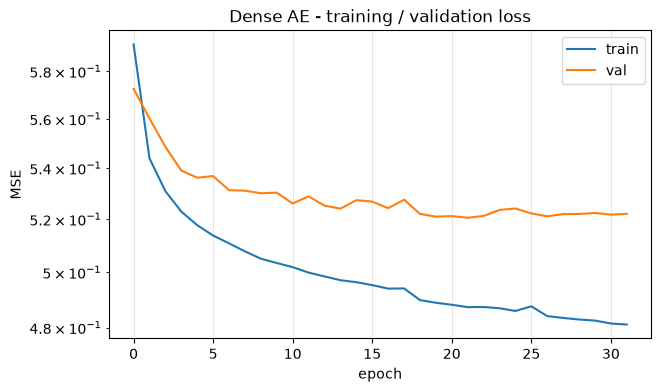

In [11]:
def build_dense_autoencoder(input_dim=D_IN, latent_dim=DENSE_LATENT, hidden=DENSE_HIDDEN):
    inp = layers.Input(shape=(input_dim,), name="stacked_frames")
    x = inp
    for h in hidden:                                    # encoder
        x = layers.Dense(h)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.Dense(latent_dim, name="bottleneck")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    for h in reversed(hidden):                          # decoder
        x = layers.Dense(h)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    out = layers.Dense(input_dim, name="reconstruction")(
        x)   # linear: inputs are standardized
    return Model(inp, out, name="dense_autoencoder")


dense_model = build_dense_autoencoder()
dense_model.compile(optimizer=tf.keras.optimizers.Adam(
    learning_rate=LR), loss="mse")
dense_model.summary()

dense_history = dense_model.fit(
    dense_train_ds, validation_data=dense_val_ds, epochs=EPOCHS, verbose=2,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=10, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6),
    ])

plt.figure(figsize=(7, 4))
plt.plot(dense_history.history["loss"], label="train")
plt.plot(dense_history.history["val_loss"], label="val")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.yscale("log")
plt.title("Dense AE - training / validation loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

I0000 00:00:1794880468.746958   26111 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_36', 48 bytes spill stores, 48 bytes spill loads

I0000 00:00:1794880469.212848   26110 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_32', 32 bytes spill stores, 32 bytes spill loads

I0000 00:00:1794880469.294860   26117 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_36', 832 bytes spill stores, 832 bytes spill loads

I0000 00:00:1794880469.588509   26111 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_26', 48 bytes spill stores, 48 bytes spill loads

I0000 00:00:1794880470.033890   26106 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_32', 8232 bytes spill s

[Dense 5-frame AE]
  AUC-ROC : 0.8115
  pAUC@0.1: 0.6247  (standardized)
  Threshold (P95 of healthy val): 0.660416
  F1-score: 0.3628
  Confusion matrix [rows=true, cols=pred]:
 [[202   2]
 [279  80]]


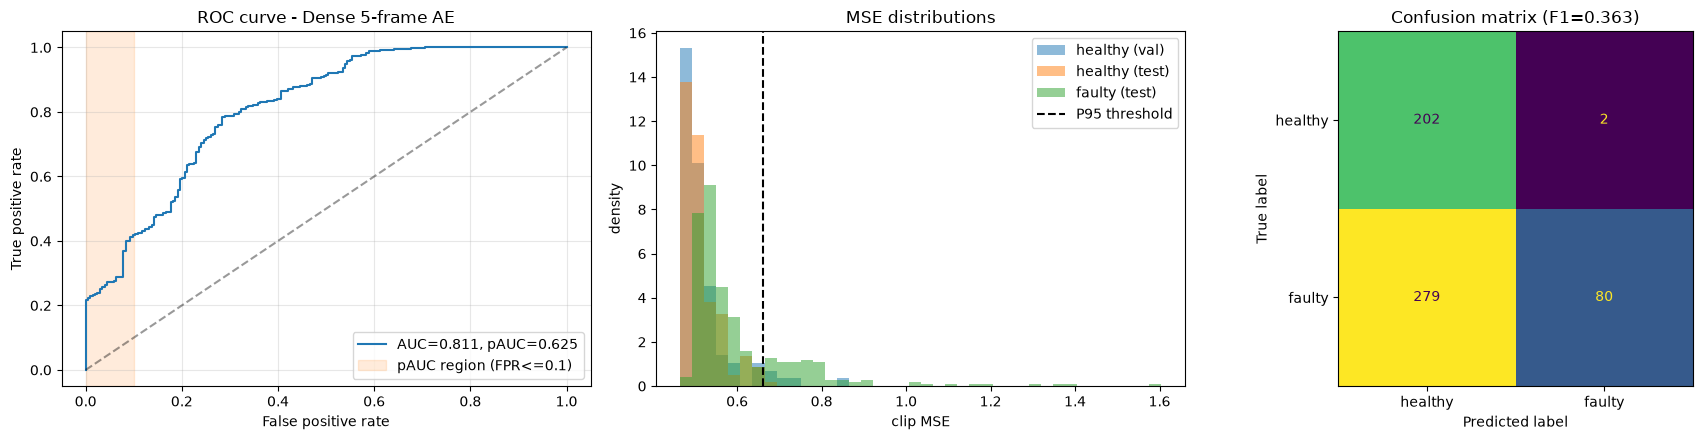

{'auc': 0.8114588453765907,
 'pauc': 0.6247459546786022,
 'f1': 0.36281179138321995,
 'threshold': np.float32(0.66041577),
 'fpr': array([0.        , 0.        , 0.        , 0.00490196, 0.00490196,
        0.00980392, 0.00980392, 0.01470588, 0.01470588, 0.01960784,
        0.01960784, 0.0245098 , 0.0245098 , 0.02941176, 0.02941176,
        0.03431373, 0.03431373, 0.03921569, 0.03921569, 0.04411765,
        0.04411765, 0.05882353, 0.05882353, 0.06372549, 0.06372549,
        0.06862745, 0.06862745, 0.07843137, 0.07843137, 0.08333333,
        0.08333333, 0.09313725, 0.09313725, 0.09803922, 0.09803922,
        0.10294118, 0.10294118, 0.10784314, 0.10784314, 0.11764706,
        0.11764706, 0.12254902, 0.12254902, 0.13235294, 0.13235294,
        0.1372549 , 0.1372549 , 0.14215686, 0.14215686, 0.14705882,
        0.14705882, 0.15196078, 0.15196078, 0.16176471, 0.16176471,
        0.16666667, 0.16666667, 0.17647059, 0.17647059, 0.18137255,
        0.18137255, 0.18627451, 0.18627451, 0.19117647

In [12]:
def dense_segment_scores(X_db, chunk=64):
    """Mean reconstruction MSE over all 5-frame vectors of each segment (stride 1)."""
    out = []
    for i in range(0, len(X_db), chunk):
        # (b, frames, D)
        V = to_context_vectors(X_db[i:i + chunk])
        b, f, d = V.shape
        flat = V.reshape(-1, d)
        rec = dense_model.predict(flat, batch_size=4096, verbose=0)
        out.append(np.mean(np.square(flat - rec),
                   axis=1).reshape(b, f).mean(axis=1))
    return np.concatenate(out)


dense_val_clip = aggregate_to_clips(dense_segment_scores(X_val_db),  ids_val)
dense_test_clip = aggregate_to_clips(dense_segment_scores(X_test_db), ids_test)
evaluate("Dense 5-frame AE", dense_val_clip, dense_test_clip)

## 10. Model comparison

Published reference points for **fan id_00** (different split protocols, so only roughly comparable):

| Source                      | Model                            | AUC                |
| --------------------------- | -------------------------------- | ------------------ |
| MIMII paper, Table 3 (6 dB) | Dense AE on 5 frames, mic 1      | 0.75               |
| DCASE 2020 dev              | Baseline AE / Dense AE / Conv AE | 0.54 / 0.57 / 0.52 |


Model                    AUC    pAUC      F1
Conv AE (spec)        0.6954  0.5535  0.2751
Dense 5-frame AE      0.8115  0.6247  0.3628


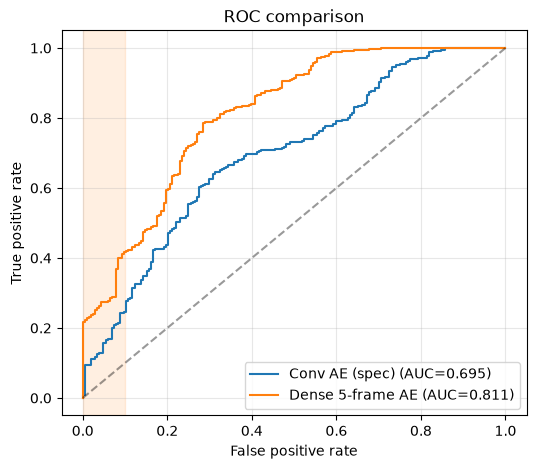

In [13]:
print(f"{'Model':<20}{'AUC':>8}{'pAUC':>8}{'F1':>8}")
for name, r in results.items():
    print(f"{name:<20}{r['auc']:>8.4f}{r['pauc']:>8.4f}{r['f1']:>8.4f}")

plt.figure(figsize=(6, 5))
for name, r in results.items():
    plt.plot(r["fpr"], r["tpr"], label=f"{name} (AUC={r['auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.axvspan(0, 0.1, color="tab:orange", alpha=0.12)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()